<a href="https://colab.research.google.com/github/kouheisia/PC1/blob/main/Gr12DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlopen
from io import BytesIO
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [ ]:
print("Downloading Student Performance Dataset...")

url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = urlopen(url).read()

with zipfile.ZipFile(BytesIO(response)) as dataset_zip:
    if "student.zip" in dataset_zip.namelist():
        nested_zip_data = dataset_zip.read("student.zip")
        with zipfile.ZipFile(BytesIO(nested_zip_data)) as inner_zip:
            df = pd.read_csv(inner_zip.open("student-mat.csv"), sep=";")
            print("Successfully loaded student-mat.csv!")
    else:
        df = pd.read_csv(dataset_zip.open("student-mat.csv"), sep=";")

Successfully loaded student-mat.csv!


In [ ]:
display(df.head())

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [ ]:
df["Result"] = np.where(df["G3"] >= 10, "Pass", "Fail")

In [ ]:
X = df.drop(columns=["G1", "G2", "G3", "Result"])
y = df["Result"]

In [ ]:
print(y.value_counts())

Result
Pass    265
Fail    130
Name: count, dtype: int64


In [ ]:
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=5,
        random_state=42
    ))
])

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
comparison = pd.DataFrame({
    "Actual Result": y_test.values,
    "Predicted Result": y_pred
})

display(comparison.head(20))

,Actual Result,Predicted Result
0,Pass,Fail
1,Fail,Fail
2,Pass,Pass
3,Pass,Pass
4,Pass,Pass
5,Pass,Pass
6,Pass,Pass
7,Fail,Fail
8,Pass,Pass
9,Pass,Pass


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 65.82%


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    labels=["Fail", "Pass"],
    target_names=["Fail", "Pass"],
    zero_division=0
))

              precision    recall  f1-score   support

        Fail       0.48      0.42      0.45        26
        Pass       0.73      0.77      0.75        53

    accuracy                           0.66        79
   macro avg       0.61      0.60      0.60        79
weighted avg       0.65      0.66      0.65        79



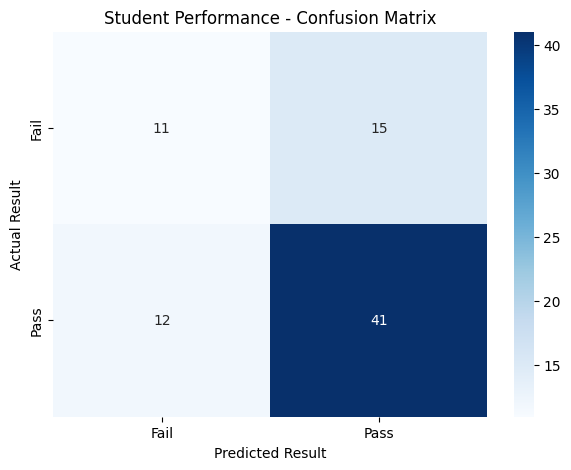

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=["Fail", "Pass"])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.title("Student Performance - Confusion Matrix")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()

In [ ]:
trained_tree = model.named_steps["classifier"]

feature_names = (
    model.named_steps["preprocessor"].get_feature_names_out()
)

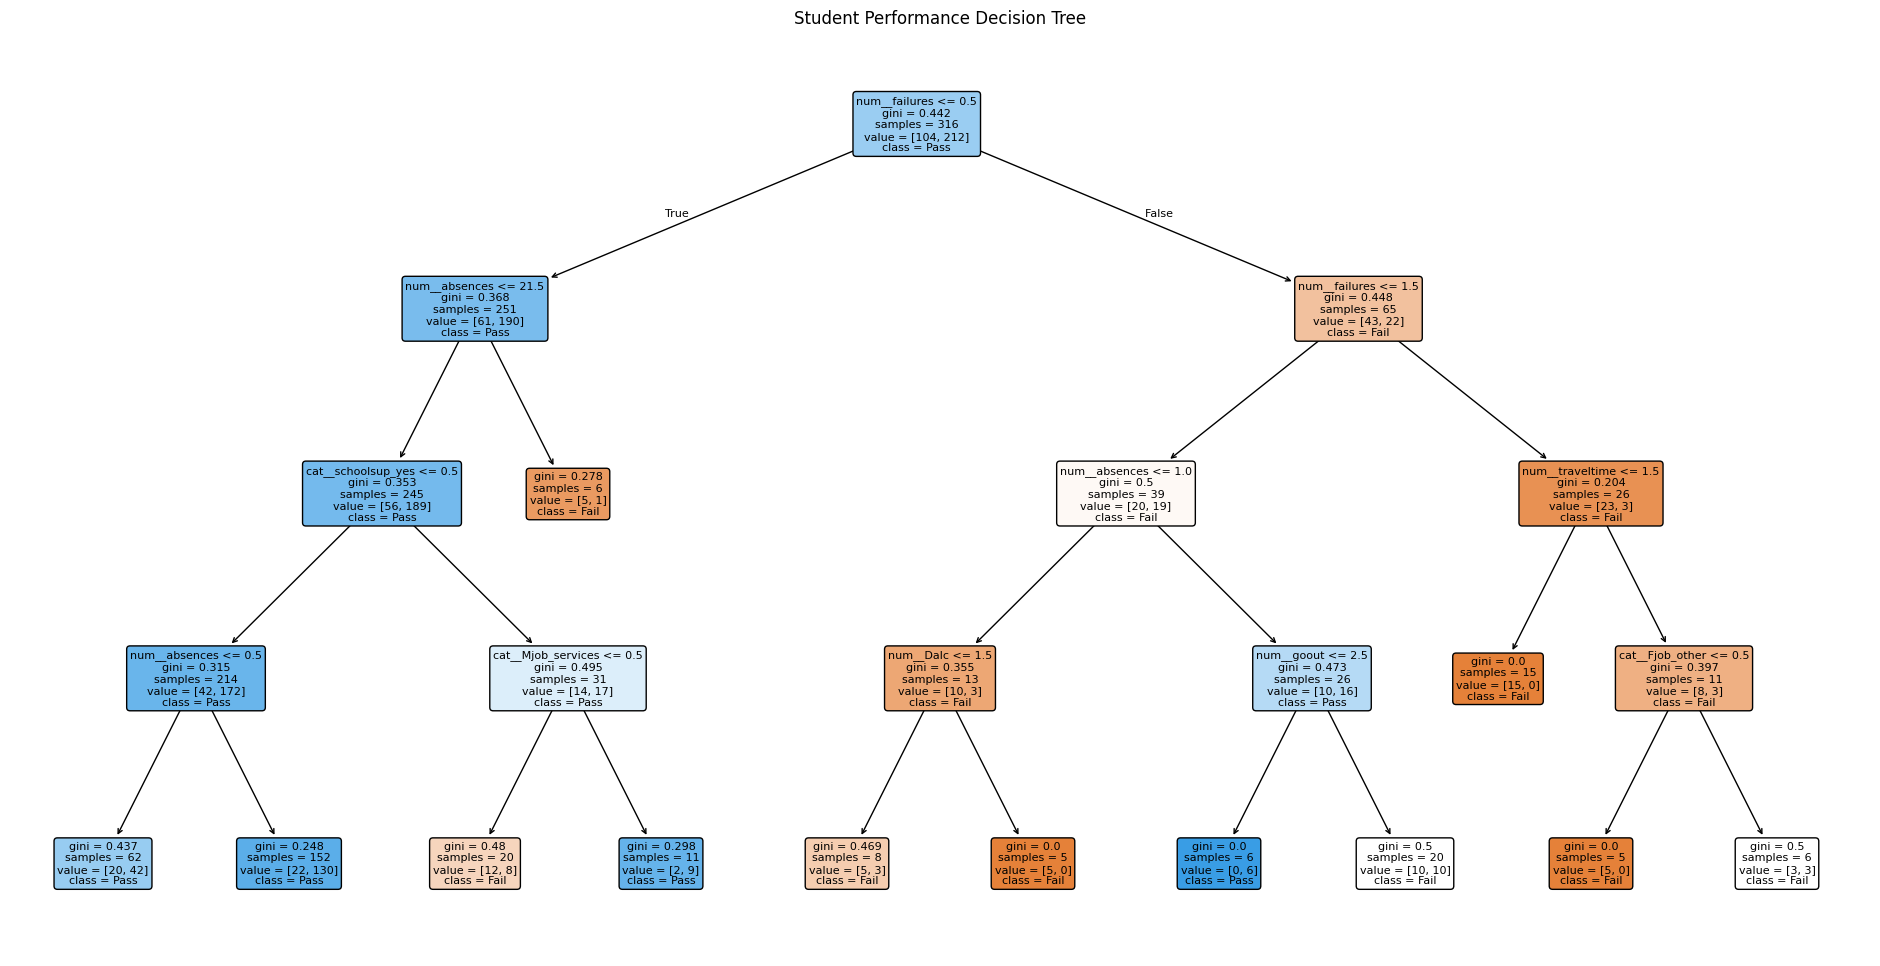

In [ ]:
plt.figure(figsize=(24, 12))

plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Student Performance Decision Tree")
plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_tree.feature_importances_
})

In [ ]:
importance = importance.sort_values(
    by="Importance",
    ascending=False
)
display(importance.head(10))

,Feature,Importance
5,num__failures,0.514602
12,num__absences,0.221329
41,cat__schoolsup_yes,0.081126
26,cat__Mjob_services,0.057025
8,num__goout,0.053018
30,cat__Fjob_other,0.031329
3,num__traveltime,0.021689
9,num__Dalc,0.019882
7,num__freetime,0.000000
6,num__famrel,0.000000


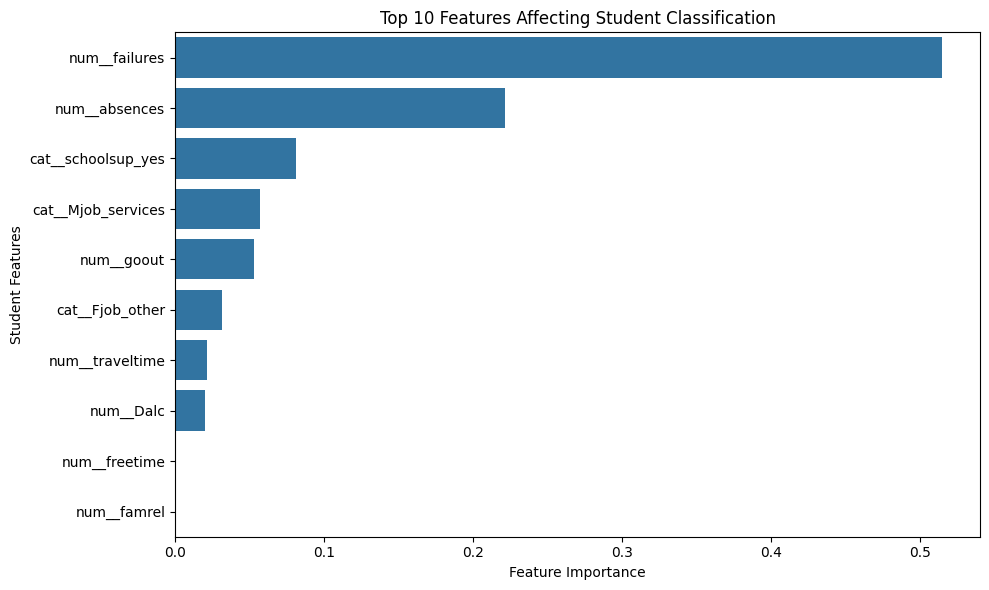

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features Affecting Student Classification")
plt.xlabel("Feature Importance")
plt.ylabel("Student Features")
plt.tight_layout()
plt.show()